In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [3]:
import os
import torch
import torchvision
import torchvision.transforms as transforms

from PIL import Image
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
GPU available: True


In [4]:
import os

DATASET_PATH = (
    "/kaggle/input/datasets/vipoooool/"
    "new-plant-diseases-dataset/"
    "New Plant Diseases Dataset(Augmented)/"
    "New Plant Diseases Dataset(Augmented)"
)

TRAIN_PATH = os.path.join(DATASET_PATH, "train")
VALID_PATH = os.path.join(DATASET_PATH, "valid")

print("Training path exists:", os.path.exists(TRAIN_PATH))
print("Validation path exists:", os.path.exists(VALID_PATH))

print("Training classes:", len(os.listdir(TRAIN_PATH)))
print("Validation classes:", len(os.listdir(VALID_PATH)))

Training path exists: True
Validation path exists: True
Training classes: 38
Validation classes: 38


Class: Apple___Apple_scab
Image name: 00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG
Original image size: (256, 256)
Image mode: RGB


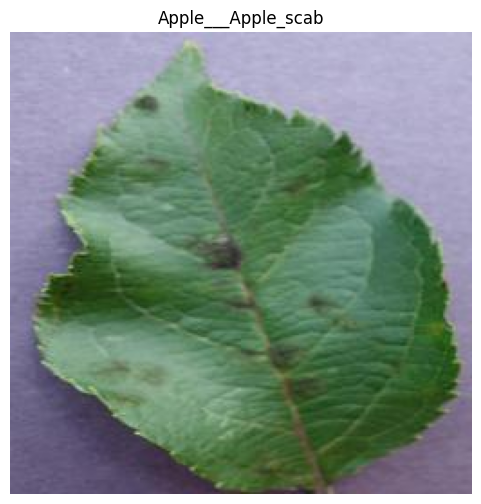

In [5]:
import os
from PIL import Image
import matplotlib.pyplot as plt

# Select the first class
classes = sorted(os.listdir(TRAIN_PATH))
sample_class = classes[0]

# Get an image from that class
class_path = os.path.join(TRAIN_PATH, sample_class)
image_name = os.listdir(class_path)[0]
image_path = os.path.join(class_path, image_name)

# Load image
image = Image.open(image_path)

print("Class:", sample_class)
print("Image name:", image_name)
print("Original image size:", image.size)
print("Image mode:", image.mode)

# Display image
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title(sample_class)
plt.axis("off")
plt.show()

In [6]:
from torchvision import transforms

# Basic preprocessing pipeline
preprocessing_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# Apply preprocessing
processed_image = preprocessing_transform(image)

print("Original image size:", image.size)
print("Processed tensor shape:", processed_image.shape)
print("Tensor data type:", processed_image.dtype)
print("Minimum pixel value:", processed_image.min().item())
print("Maximum pixel value:", processed_image.max().item())

Original image size: (256, 256)
Processed tensor shape: torch.Size([3, 224, 224])
Tensor data type: torch.float32
Minimum pixel value: 0.0117647061124444
Maximum pixel value: 0.8784313797950745


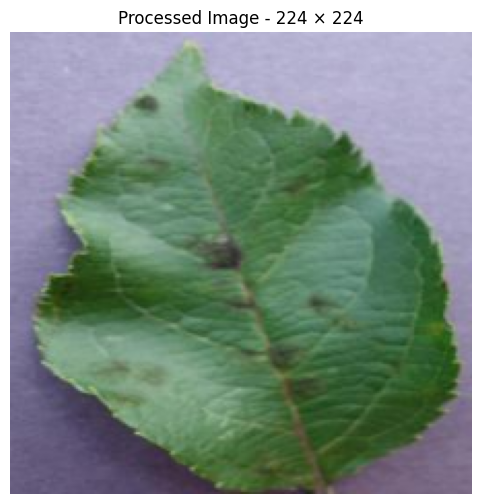

In [7]:
import matplotlib.pyplot as plt

# Convert tensor back to image format for visualization
processed_image_display = processed_image.permute(1, 2, 0).numpy()

plt.figure(figsize=(6, 6))
plt.imshow(processed_image_display)
plt.title("Processed Image - 224 × 224")
plt.axis("off")
plt.show()

In [8]:
import torch
from torchvision import transforms

# Common ImageNet normalization values
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

def get_preprocessing_transform(
    image_size=224,
    mean=IMAGENET_MEAN,
    std=IMAGENET_STD
):
    """
    Creates a reusable image preprocessing pipeline.

    Parameters:
        image_size: Target image dimensions.
        mean: RGB channel mean values.
        std: RGB channel standard deviation values.

    Returns:
        A torchvision preprocessing transformation.
    """

    transform = transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std)
    ])

    return transform

In [9]:
# Create preprocessing pipeline
preprocess = get_preprocessing_transform(image_size=224)

# Process the previously loaded image
normalized_image = preprocess(image)

print("Processed shape:", normalized_image.shape)
print("Data type:", normalized_image.dtype)
print("Minimum value:", normalized_image.min().item())
print("Maximum value:", normalized_image.max().item())

Processed shape: torch.Size([3, 224, 224])
Data type: torch.float32
Minimum value: -1.7582842111587524
Maximum value: 2.0996952056884766


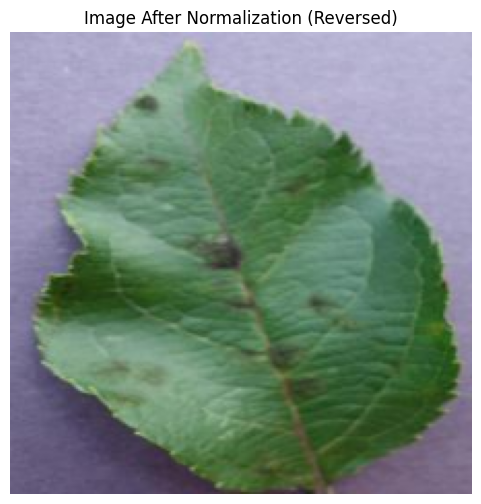

In [10]:
import matplotlib.pyplot as plt

# Reverse normalization
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

display_image = normalized_image * std + mean

# Convert to HWC format
display_image = display_image.permute(1, 2, 0).numpy()

# Keep pixel values within display range
display_image = display_image.clip(0, 1)

plt.figure(figsize=(6, 6))
plt.imshow(display_image)
plt.title("Image After Normalization (Reversed)")
plt.axis("off")
plt.show()

In [13]:
#1. Create PyTorch datasets

from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

# Preprocessing configuration
IMAGE_SIZE = 224
BATCH_SIZE = 32

# Common preprocessing for initial experiments
train_transform = get_preprocessing_transform(
    image_size=IMAGE_SIZE
)

valid_transform = get_preprocessing_transform(
    image_size=IMAGE_SIZE
)

# Load datasets
train_dataset = ImageFolder(
    root=TRAIN_PATH,
    transform=train_transform
)

valid_dataset = ImageFolder(
    root=VALID_PATH,
    transform=valid_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(valid_dataset))
print("Number of classes:", len(train_dataset.classes))

#2. Verify class mappings

print("Training classes:")
print(train_dataset.classes)

print("\nValidation classes:")
print(valid_dataset.classes)

# Verify class mappings are identical
assert train_dataset.class_to_idx == valid_dataset.class_to_idx

print("\nClass mappings match!")


#3. Create DataLoaders

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")


#4. Inspect one batch

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Labels:", labels[:10])

Training samples: 70295
Validation samples: 17572
Number of classes: 38
Training classes:
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato__

In [14]:
#Verify GPU batch compatibility

# Select available device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

# Move one batch to the device
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

print("Images device:", images.device)
print("Labels device:", labels.device)
print("Batch shape:", images.shape)

Selected device: cuda
Images device: cuda:0
Labels device: cuda:0
Batch shape: torch.Size([32, 3, 224, 224])


Finalize the preprocessing configuration

In [16]:
#1. Create a preprocessing configuration

PREPROCESS_CONFIG = {
    "image_size": 224,
    "batch_size": 32,
    "normalization": "ImageNet",
    "mean": IMAGENET_MEAN,
    "std": IMAGENET_STD,
    "color_mode": "RGB"
}

print("Preprocessing Configuration:")
for key, value in PREPROCESS_CONFIG.items():
    print(f"{key}: {value}")

Preprocessing Configuration:
image_size: 224
batch_size: 32
normalization: ImageNet
mean: (0.485, 0.456, 0.406)
std: (0.229, 0.224, 0.225)
color_mode: RGB


In [17]:
#2. Save the class mapping

import json

class_mapping = train_dataset.class_to_idx

with open("class_mapping.json", "w") as file:
    json.dump(class_mapping, file, indent=4)

print("Class mapping saved successfully!")

Class mapping saved successfully!


In [19]:
#3. Check the saved file
with open("class_mapping.json", "r") as file:
    loaded_mapping = json.load(file)

print("Total classes:", len(loaded_mapping))
print("Example mapping:", list(loaded_mapping.items())[:5])

Total classes: 38
Example mapping: [('Apple___Apple_scab', 0), ('Apple___Black_rot', 1), ('Apple___Cedar_apple_rust', 2), ('Apple___healthy', 3), ('Blueberry___healthy', 4)]


final preprocessing code

In [2]:

import torch
from torchvision import transforms

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def get_preprocessing_transform(
    image_size=224,
    mean=IMAGENET_MEAN,
    std=IMAGENET_STD
):
    """
    Create a reusable image preprocessing pipeline.

    Args:
        image_size: Target image dimensions.
        mean: RGB channel mean values.
        std: RGB channel standard deviation values.

    Returns:
        torchvision preprocessing transformation.
    """

    return transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std)
    ])


def get_device():
    """Return CUDA GPU if available, otherwise CPU."""
    return torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
